Experiment 2: topic shift quantification

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import ruptures as rpt
import torch
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from kvmeaning import model as M
from kvmeaning.attention_mass import span_mass
from kvmeaning.hooks import capture
from kvmeaning.spans import exp2_encode
from kvmeaning.store import load

RUN = Path(os.environ['KV_RUN']) if 'KV_RUN' in os.environ else sorted(p for p in Path('../runs').iterdir() if (p / 'exp2').exists())[-1]
FIG = Path(os.environ.get('KV_FIG', '../figures/exp2'))
FIG.mkdir(parents=True, exist_ok=True)
DATA = Path('../data')
REPS = ('v', 'k_pre', 'k_post', 'resid')
DLG = {d['id']: d for d in map(json.loads, (DATA / 'exp2_dialogues.jsonl').read_text().splitlines())}
PAIRS = ('soccer-baseball', 'soccer-quantum')
CONDS = ('S1', 'S2', 'S3', 'S5', 'S6')
IDS = [f'{p}-{c}' for p in PAIRS for c in CONDS] + ['soccer-S4']


def flat(t, r):
    # K/V heads are concatenated so every representation is [L, T, D]; resid drops the embedding row.
    return t[r][1:].float() if r == 'resid' else t[r].float().permute(0, 2, 1, 3).flatten(2)


X, META, MASS = {}, {}, {}
for i in IDS:
    t, m = load(RUN / 'exp2' / i)
    X[i] = {r: flat(t, r) for r in REPS}
    META[i] = m
NL = X[IDS[0]]['v'].shape[0]


def content_idx(i):
    return np.concatenate([np.arange(a, b) for a, b in META[i]['spans'].values()])


def turn_tok(i, k):
    return META[i]['spans'][f'turn_{k}'][0] if k is not None else None


EV_COLOR = {'declaration': 'k', 'B onset': 'r', 'intermediate': 'orange', 'return to A': 'g'}


def events(i):
    d = DLG[i]
    ev = {'declaration': d.get('declaration_turn'), 'B onset': d.get('b_content_turn'),
          'intermediate': d.get('intermediate_turn'), 'return to A': d.get('return_turn')}
    return {k: v for k, v in ev.items() if v is not None}


# Turns 0-11 (soccer A) are token-identical in every dialogue, so the A span is the same key range everywhere.
A_SPAN = (1, META['soccer-S4']['spans']['turn_11'][1])
assert all(META[i]['ids'][:A_SPAN[1]] == META['soccer-S4']['ids'][:A_SPAN[1]] for i in IDS)
print(RUN.name, NL, 'layers;', {i: len(META[i]['ids']) for i in IDS}, 'A span', A_SPAN)

20261014-093549-0.6B 28 layers; {'soccer-baseball-S1': 590, 'soccer-baseball-S2': 548, 'soccer-baseball-S3': 586, 'soccer-baseball-S5': 681, 'soccer-baseball-S6': 645, 'soccer-quantum-S1': 574, 'soccer-quantum-S2': 531, 'soccer-quantum-S3': 587, 'soccer-quantum-S5': 660, 'soccer-quantum-S6': 626, 'soccer-S4': 544} A span (1, 281)


In [2]:
# Raw activations share a large common direction (anisotropy) that dominates cosine; subtracting
# the per-layer mean over all content tokens of all dialogues removes it.
MU = {r: torch.cat([X[i][r][:, content_idx(i)] for i in IDS], 1).mean(1, keepdim=True) for r in REPS}
XC = {i: {r: X[i][r] - MU[r] for r in REPS} for i in IDS}


def exchange_vecs(i, r):
    n = len(DLG[i]['turns']) // 2
    sp = META[i]['spans']
    return torch.stack([torch.cat([XC[i][r][:, slice(*sp[f'turn_{2*j+u}'])] for u in (0, 1)], 1).mean(1) for j in range(n)], 1)


EX = {(i, r): exchange_vecs(i, r) for i in IDS for r in REPS}  # [L, n_exchange, D]


def adj_dist(v):
    return 1 - F.cosine_similarity(v[:, 1:], v[:, :-1], dim=-1)  # [L, n-1], entry j = exchange j vs j+1


ADJ = {k: adj_dist(v) for k, v in EX.items()}
# Noise floor: adjacent-exchange distances inside the no-shift control (all-soccer).
FLOOR = {r: (ADJ['soccer-S4', r].mean(1), ADJ['soccer-S4', r].std(1)) for r in REPS}

## M1. Adjacent distance (token / turn)

soccer-baseball-S1 {'v': 1.56, 'k_pre': 1.63, 'k_post': 1.9, 'resid': 1.42} best layer {'v': 27, 'k_pre': 4, 'k_post': 4, 'resid': 24}
soccer-baseball-S2 {'v': 1.09, 'k_pre': 1.19, 'k_post': 1.42, 'resid': 1.1} best layer {'v': 26, 'k_pre': 5, 'k_post': 4, 'resid': 24}
soccer-baseball-S3 {'v': 1.56, 'k_pre': 1.63, 'k_post': 1.9, 'resid': 1.42} best layer {'v': 27, 'k_pre': 4, 'k_post': 4, 'resid': 24}
soccer-baseball-S5 {'v': 1.31, 'k_pre': 1.45, 'k_post': 1.58, 'resid': 1.31} best layer {'v': 27, 'k_pre': 0, 'k_post': 0, 'resid': 27}
soccer-baseball-S6 {'v': 1.09, 'k_pre': 1.19, 'k_post': 1.42, 'resid': 1.1} best layer {'v': 26, 'k_pre': 5, 'k_post': 4, 'resid': 24}
soccer-quantum-S1 {'v': 1.59, 'k_pre': 1.64, 'k_post': 1.89, 'resid': 1.45} best layer {'v': 27, 'k_pre': 4, 'k_post': 4, 'resid': 24}
soccer-quantum-S2 {'v': 1.71, 'k_pre': 1.71, 'k_post': 1.75, 'resid': 1.62} best layer {'v': 27, 'k_pre': 4, 'k_post': 4, 'resid': 27}
soccer-quantum-S3 {'v': 1.59, 'k_pre': 1.64, 'k_post':

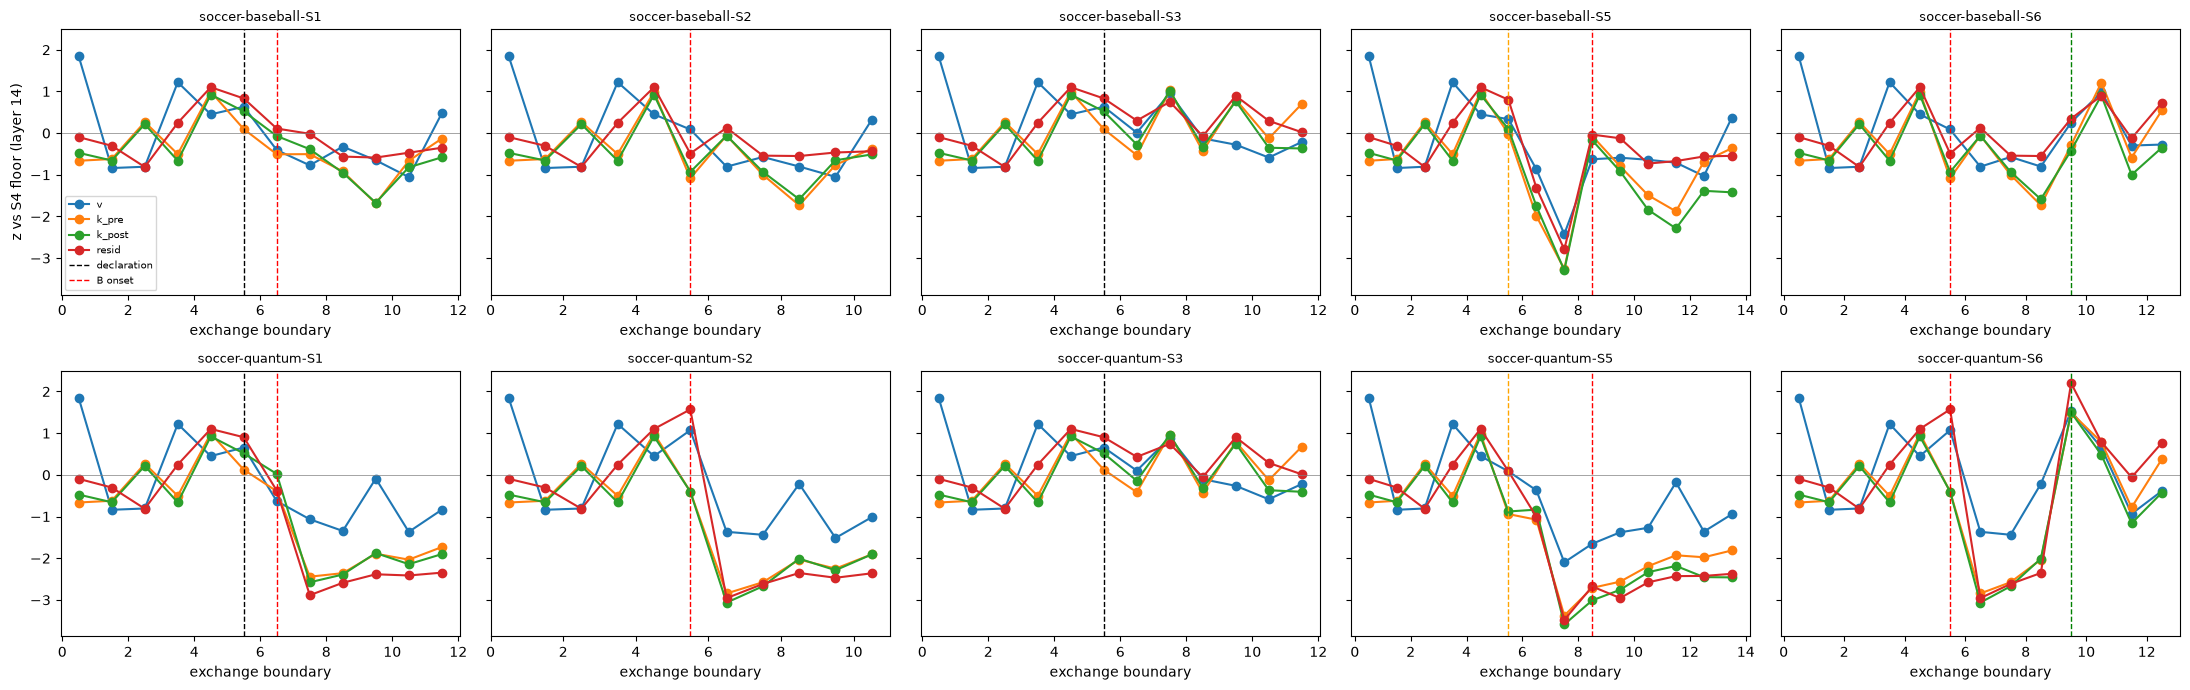

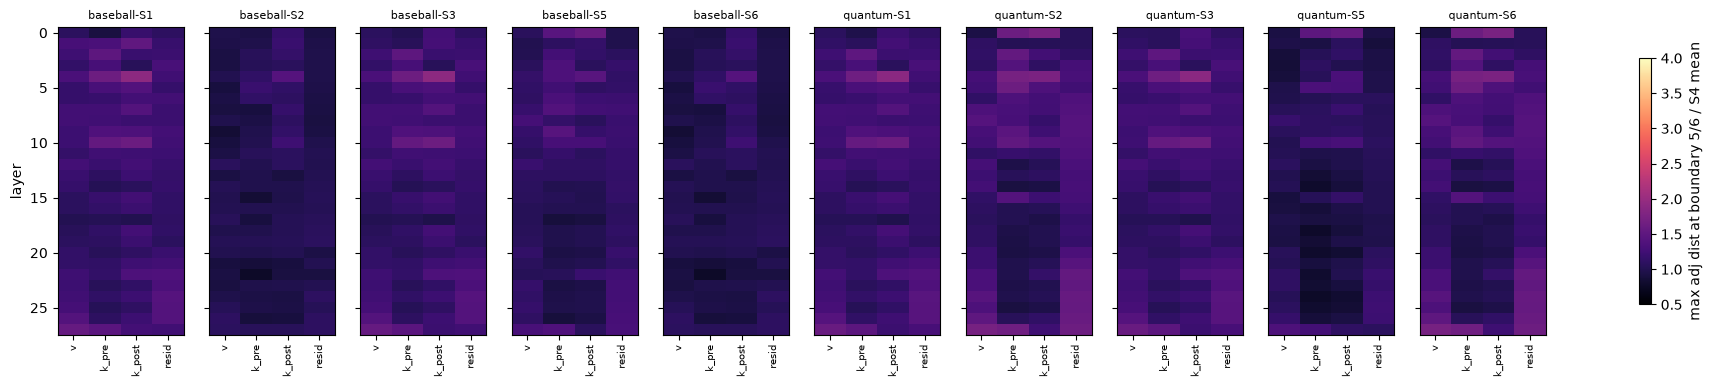

In [3]:
W = 24


def smooth(x, w=W):
    return np.convolve(x, np.ones(w) / w, mode='same')


def tok_adj(i, r, layer):
    idx = content_idx(i)
    x = XC[i][r][layer, idx]
    return idx[1:], (1 - F.cosine_similarity(x[1:], x[:-1], dim=-1)).numpy()


def vlines(ax, i, xs='tok'):
    for name, k in events(i).items():
        c = EV_COLOR[name]
        x = turn_tok(i, k) if xs == 'tok' else k // 2 - 0.5
        ax.axvline(x, color=c, ls='--', lw=1, label=name)


# Ratio at each boundary = adjacent distance / S4 floor mean, per layer and representation.
def ratio(i, r):
    m, _ = FLOOR[r]
    return ADJ[i, r] / m[:, None]


fig, axes = plt.subplots(len(PAIRS) * len(CONDS) // 5, 5, figsize=(22, 7), sharey=True)
for ax, i in zip(axes.flat, [i for i in IDS if i != 'soccer-S4']):
    for r in REPS:
        z = ((ADJ[i, r] - FLOOR[r][0][:, None]) / FLOOR[r][1][:, None])[NL // 2].numpy()
        ax.plot(np.arange(len(z)) + 0.5, z, marker='o', label=r)
    vlines(ax, i, 'ex')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(i, fontsize=9)
    ax.set_xlabel('exchange boundary')
axes[0, 0].set_ylabel(f'z vs S4 floor (layer {NL//2})')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / 'm1_turn_distance.png', dpi=110)

# Layer x representation map of the peak boundary ratio after the A block, per condition.
SHIFT_B = 5  # boundary between exchange 5 (last pure-A) and exchange 6
fig, axes = plt.subplots(1, len(IDS) - 1, figsize=(24, 4), sharey=True)
PEAK = {}
for ax, i in zip(axes, [i for i in IDS if i != 'soccer-S4']):
    m = np.stack([ratio(i, r)[:, SHIFT_B:SHIFT_B + 2].max(1).values.numpy() for r in REPS], 1)
    PEAK[i] = m
    im = ax.imshow(m, aspect='auto', cmap='magma', vmin=0.5, vmax=4)
    ax.set_xticks(range(4), REPS, rotation=90, fontsize=7)
    ax.set_title(i.replace('soccer-', ''), fontsize=8)
axes[0].set_ylabel('layer')
fig.colorbar(im, ax=axes, shrink=0.8, label='max adj dist at boundary 5/6 / S4 mean')
fig.savefig(FIG / 'm1_layer_repr.png', dpi=110, bbox_inches='tight')

for i in IDS:
    print(i, {r: round(float(PEAK.get(i, np.zeros((NL, 4)))[:, k].max()), 2) for k, r in enumerate(REPS)},
          'best layer', {r: int(PEAK.get(i, np.zeros((NL, 4)))[:, k].argmax()) for k, r in enumerate(REPS)})
print('S4 boundary 5/6 ratio (layer max):', {r: round(float(ratio('soccer-S4', r)[:, SHIFT_B:SHIFT_B+2].max()), 2) for r in REPS})

In [4]:
# Per-boundary table at the middle layer: declaration boundary (5->6) and next (6->7).
L_MID = NL // 2
rows = []
for i in IDS:
    rows.append((i, *[float(ratio(i, r)[L_MID, b]) for r in REPS for b in (5, 6)]))
print('ratio @ layer', L_MID, 'cols:', [f'{r}@{b}' for r in REPS for b in (5, 6)])
for row in rows:
    print(row[0].ljust(22), ' '.join(f'{x:5.2f}' for x in row[1:]))
# Token-level: mean smoothed adjacent distance in the 48 content tokens after each event / S4 mean.
for r in REPS:
    for l in (4, L_MID, NL - 4):
        base = tok_adj('soccer-S4', r, l)[1].mean()
        row = {}
        for i in IDS:
            x, d = tok_adj(i, r, l)
            for name, k in events(i).items():
                t0 = turn_tok(i, k)
                row[f"{i.replace('soccer-', '')}:{name[:4]}"] = round(float(d[(x >= t0)][:48].mean() / base), 2)
            row[f"{i.replace('soccer-', '')}:A"] = round(float(d[x < A_SPAN[1]].mean() / base), 2)
        print(r, l, row)

ratio @ layer 14 cols: ['v@5', 'v@6', 'k_pre@5', 'k_pre@6', 'k_post@5', 'k_post@6', 'resid@5', 'resid@6']
soccer-baseball-S1      1.16  0.89  1.02  0.89  1.07  0.99  1.16  1.02
soccer-baseball-S2      1.02  0.79  0.76  0.99  0.88  0.99  0.91  1.02
soccer-baseball-S3      1.16  1.00  1.02  0.88  1.07  0.96  1.16  1.06
soccer-baseball-S5      1.09  0.77  1.00  0.56  1.01  0.77  1.15  0.75
soccer-baseball-S6      1.02  0.79  0.76  0.99  0.88  0.99  0.91  1.02
soccer-quantum-S1       1.17  0.84  1.03  0.91  1.07  1.00  1.17  0.93
soccer-quantum-S2       1.28  0.64  0.91  0.37  0.95  0.60  1.30  0.44
soccer-quantum-S3       1.17  1.03  1.03  0.91  1.07  0.98  1.17  1.08
soccer-quantum-S5       1.02  0.90  0.79  0.76  0.89  0.89  1.02  0.81
soccer-quantum-S6       1.28  0.64  0.91  0.37  0.95  0.60  1.30  0.44
soccer-S4               0.66  1.27  0.53  1.29  0.73  1.21  0.53  1.18
v 4 {'baseball-S1:decl': 0.9, 'baseball-S1:B on': 1.01, 'baseball-S1:A': 1.0, 'baseball-S2:B on': 1.02, 'baseball

## M2. Attention mass on pre-shift span

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

post-shift (turns 14-23) mean A-mass, head mean, layers avg / min-layer:
soccer-baseball-S1     0.233 delta vs S4 -0.025 most negative layer 21 -0.080
soccer-baseball-S2     0.250 delta vs S4 -0.008 most negative layer 20 -0.043
soccer-baseball-S3     0.234 delta vs S4 -0.024 most negative layer 21 -0.059
soccer-baseball-S5     0.225 delta vs S4 -0.033 most negative layer 20 -0.081
soccer-baseball-S6     0.249 delta vs S4 -0.009 most negative layer 20 -0.032
soccer-quantum-S1      0.175 delta vs S4 -0.082 most negative layer 21 -0.164
soccer-quantum-S2      0.188 delta vs S4 -0.070 most negative layer 13 -0.138
soccer-quantum-S3      0.238 delta vs S4 -0.020 most negative layer 21 -0.040
soccer-quantum-S5      0.173 delta vs S4 -0.085 most negative layer 21 -0.154
soccer-quantum-S6      0.222 delta vs S4 -0.036 most negative layer 12 -0.080
soccer-S4              0.257 delta vs S4 +0.000 most negative layer 0 +0.000


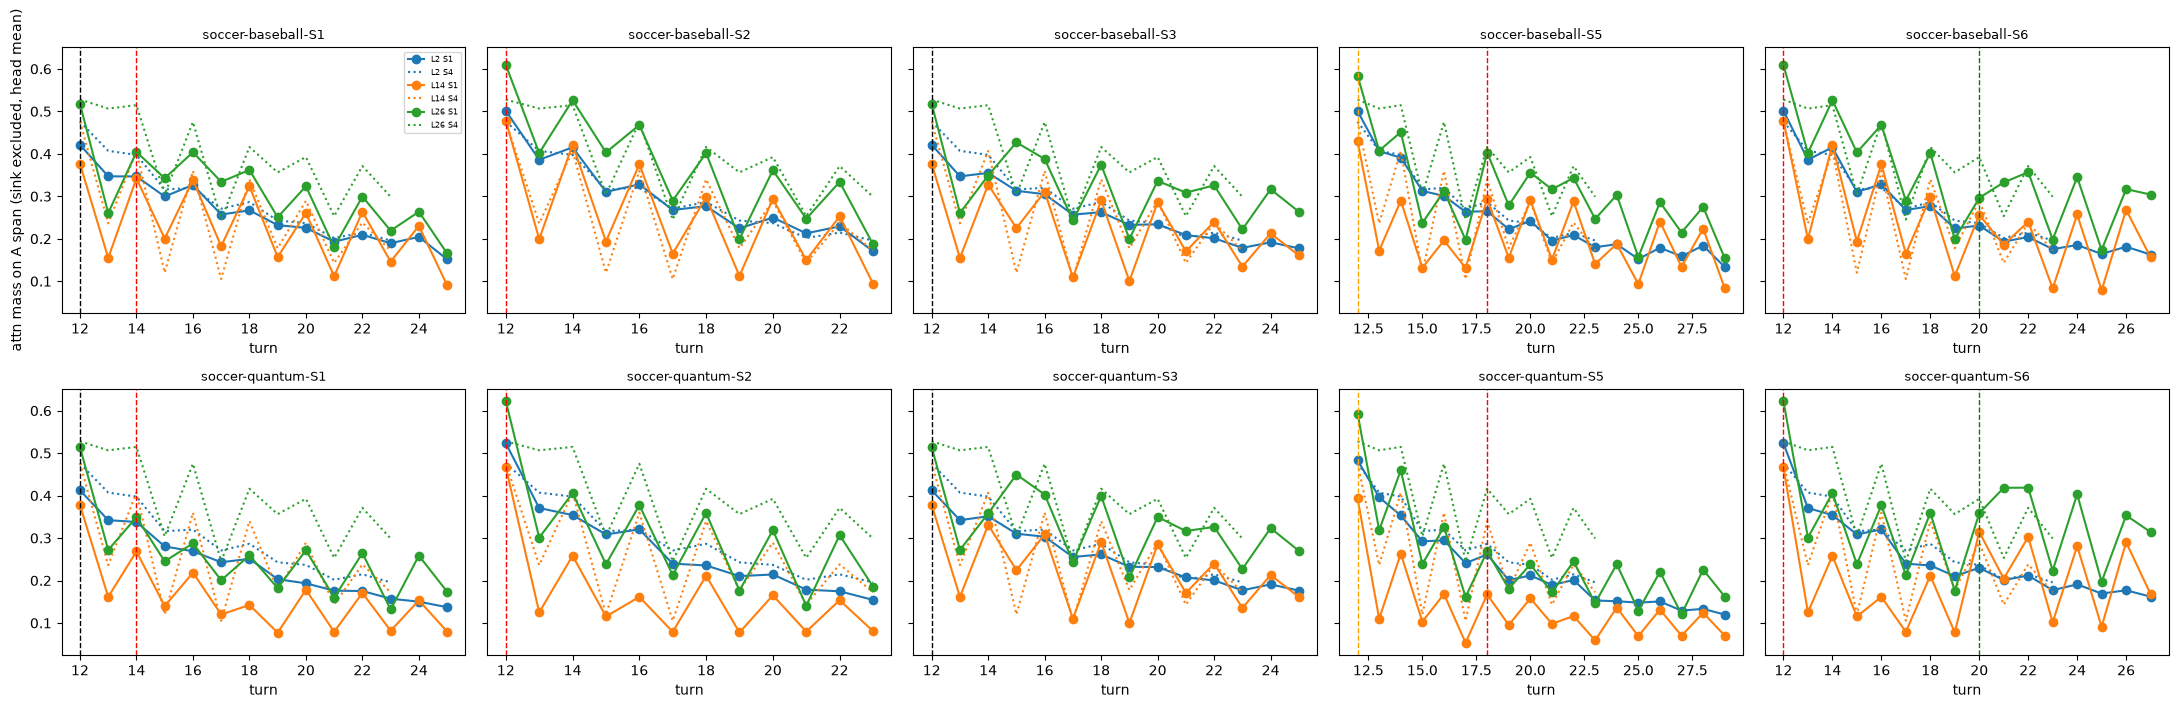

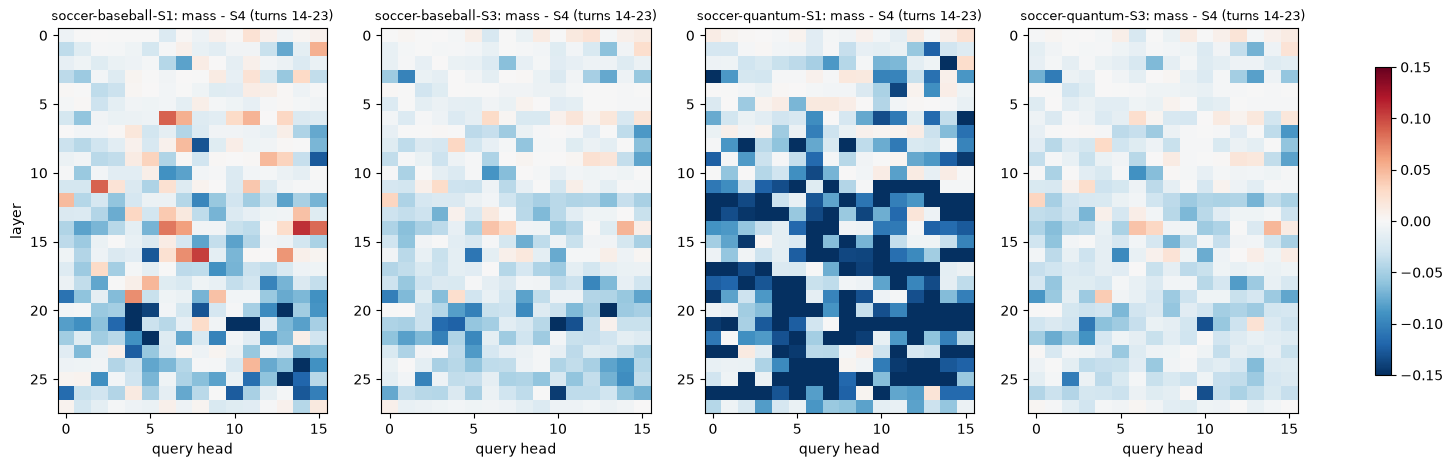

In [5]:
model, tok = M.load(os.environ.get('KV_MODEL', '0.6B'))
for i in IDS:
    assert exp2_encode(tok, DLG[i]['turns']).ids == META[i]['ids']
    cap = capture(model, torch.tensor([META[i]['ids']]))
    MASS[i] = torch.stack([span_mass(cap.q_post[l], cap.k_post[l], {'A': A_SPAN})['A'] for l in range(NL)])  # [L, Hq, T]
    del cap


def turn_mass(i, layer=None):
    m = MASS[i].mean(1) if layer is None else MASS[i][layer]
    n = len(DLG[i]['turns'])
    return torch.stack([m[..., slice(*META[i]['spans'][f'turn_{k}'])].mean(-1) for k in range(12, n)], -1)


fig, axes = plt.subplots(2, 5, figsize=(22, 7), sharey=True)
for ax, i in zip(axes.flat, [i for i in IDS if i != 'soccer-S4']):
    for l in (2, NL // 2, NL - 2):
        tm, ts = turn_mass(i)[l].numpy(), turn_mass('soccer-S4')[l].numpy()
        k = np.arange(12, 12 + len(tm))
        ax.plot(k, tm, marker='o', label=f'L{l} {i.split("-")[-1]}')
        ax.plot(np.arange(12, 12 + len(ts)), ts, ls=':', color=ax.lines[-1].get_color(), label=f'L{l} S4')
    for name, kk in events(i).items():
        ax.axvline(kk, color=EV_COLOR[name], ls='--', lw=1)
    ax.set_title(i, fontsize=9)
    ax.set_xlabel('turn')
axes[0, 0].set_ylabel('attn mass on A span (sink excluded, head mean)')
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
fig.savefig(FIG / 'm2_attn_mass_turns.png', dpi=110)

# Mean mass over the post-shift region (turns 14-23, same turn indices in S4) minus S4, per layer/head.
def post_mass(i, k0=14, k1=24):
    ks = range(k0, min(k1, len(DLG[i]['turns'])))
    return torch.stack([MASS[i][..., slice(*META[i]['spans'][f'turn_{k}'])].mean(-1) for k in ks]).mean(0)  # [L, Hq]


fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, i in zip(axes, ['soccer-baseball-S1', 'soccer-baseball-S3', 'soccer-quantum-S1', 'soccer-quantum-S3']):
    dm = (post_mass(i) - post_mass('soccer-S4')).numpy()
    im = ax.imshow(dm, aspect='auto', cmap='RdBu_r', vmin=-0.15, vmax=0.15)
    ax.set_title(f'{i}: mass - S4 (turns 14-23)', fontsize=9)
    ax.set_xlabel('query head')
axes[0].set_ylabel('layer')
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(FIG / 'm2_head_heatmap.png', dpi=110, bbox_inches='tight')

print('post-shift (turns 14-23) mean A-mass, head mean, layers avg / min-layer:')
for i in IDS:
    pm = post_mass(i).mean(1)
    d = pm - post_mass('soccer-S4').mean(1)
    print(i.ljust(22), f'{float(pm.mean()):.3f}', 'delta vs S4', f'{float(d.mean()):+.3f}', 'most negative layer', int(d.argmin()), f'{float(d.min()):+.3f}')

## M3. Trajectory (PCA / UMAP)

/Users/hwansu/toy-projects/understand-KVCache/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


soccer-baseball-S6 cos to A centroid: A 0.273 B 0.069 return 0.061 | same return texts in S4 (turns 12-19) 0.088
soccer-quantum-S6 cos to A centroid: A 0.273 B -0.209 return 0.088 | same return texts in S4 (turns 12-19) 0.088


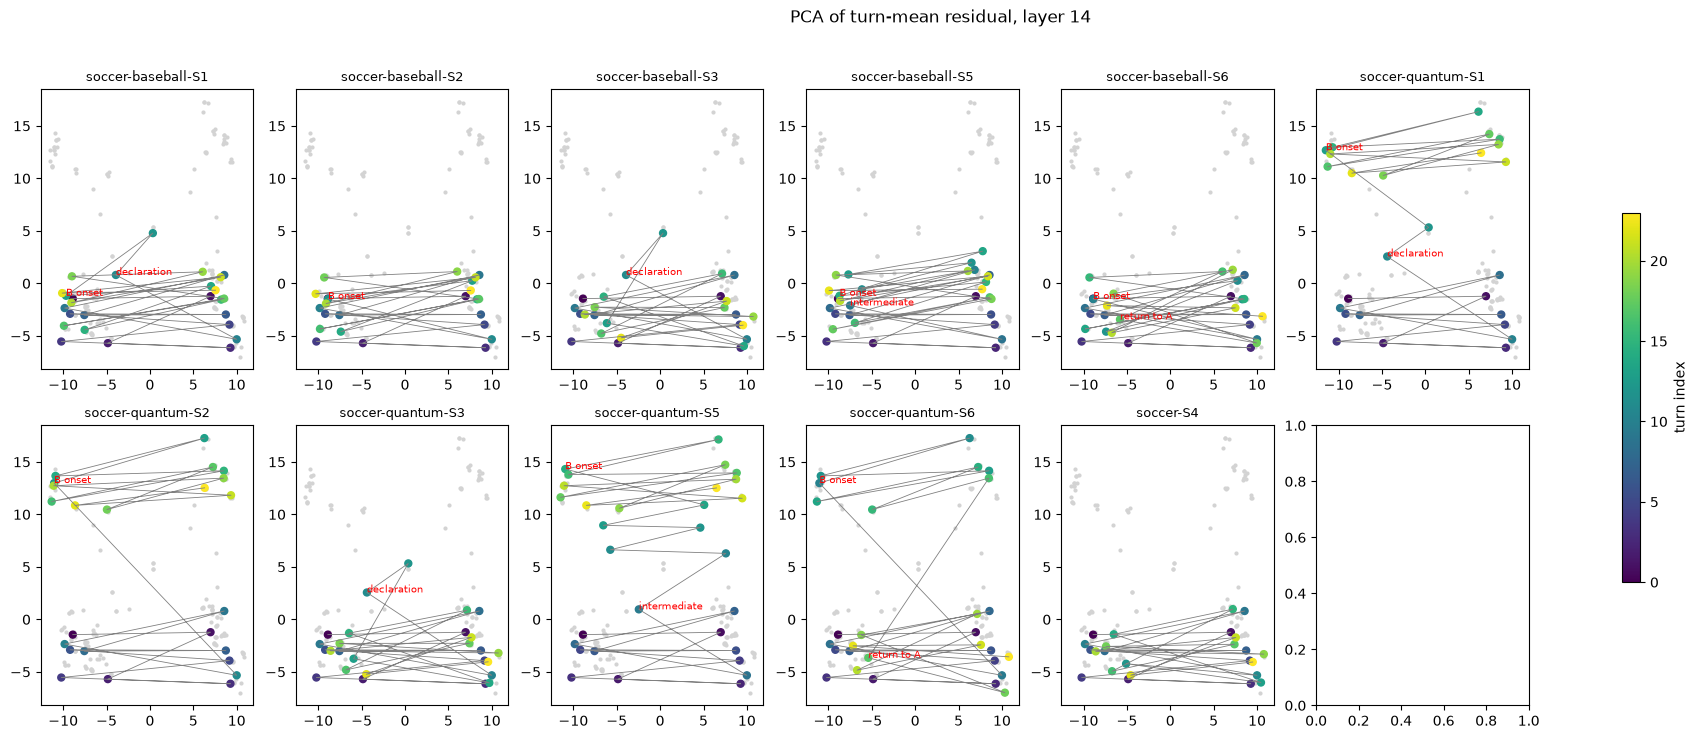

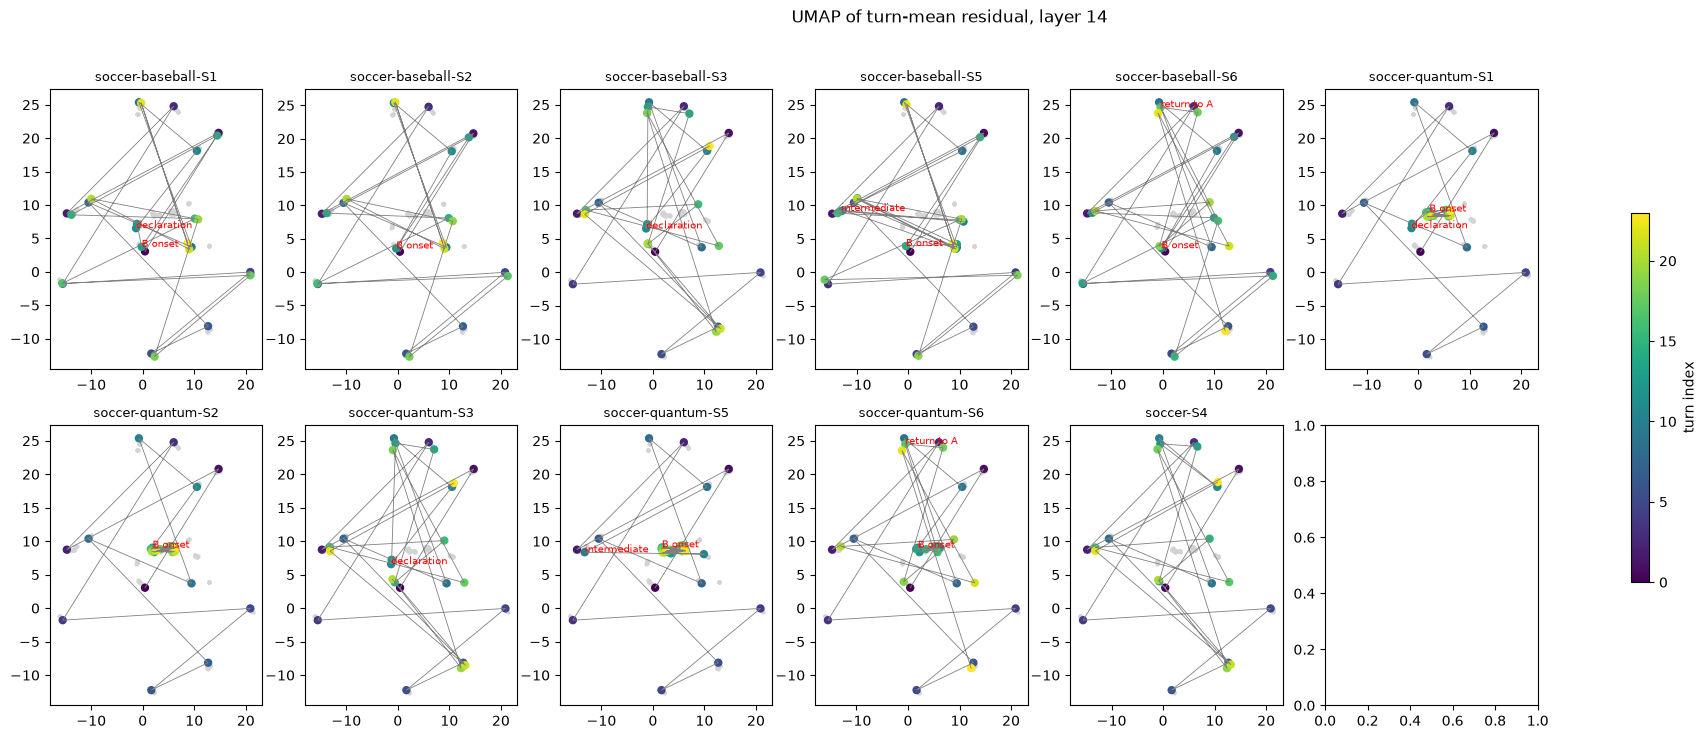

In [6]:
import umap

LT = NL // 2
TURNVEC = {}
for i in IDS:
    sp = META[i]['spans']
    TURNVEC[i] = torch.stack([XC[i]['resid'][LT, slice(*sp[f'turn_{k}'])].mean(0) for k in range(len(DLG[i]['turns']))]).numpy()
allv = np.concatenate([TURNVEC[i] for i in IDS])
proj = {'PCA': PCA(2).fit(allv).transform, 'UMAP': umap.UMAP(n_neighbors=15, random_state=0).fit(allv).transform}
for name, f in proj.items():
    fig, axes = plt.subplots(2, 6, figsize=(24, 8))
    bg = f(allv)
    for ax, i in zip(axes.flat, IDS):
        ax.scatter(bg[:, 0], bg[:, 1], s=4, color='lightgray')
        p = f(TURNVEC[i])
        ax.plot(p[:, 0], p[:, 1], color='gray', lw=0.6)
        sc = ax.scatter(p[:, 0], p[:, 1], c=np.arange(len(p)), cmap='viridis', s=25)
        for name2, k in events(i).items():
            ax.annotate(name2, p[k], fontsize=7, color='r')
        ax.set_title(i, fontsize=9)
    fig.colorbar(sc, ax=axes, shrink=0.6, label='turn index')
    fig.suptitle(f'{name} of turn-mean residual, layer {LT}')
    fig.savefig(FIG / f'm3_trajectory_{name.lower()}.png', dpi=110, bbox_inches='tight')

# Quantitative S6 check: does the return segment re-enter the A cluster? Cosine to A centroid.
for i in [f'{p}-S6' for p in PAIRS]:
    v = torch.tensor(TURNVEC[i])
    ca = v[:12].mean(0)
    c = F.cosine_similarity(v, ca[None], dim=-1).numpy()
    s4 = F.cosine_similarity(torch.tensor(TURNVEC['soccer-S4'][12:20]), ca[None], dim=-1).numpy()
    print(i, 'cos to A centroid: A', c[:12].mean().round(3), 'B', c[12:20].mean().round(3), 'return', c[20:].mean().round(3),
          '| same return texts in S4 (turns 12-19)', s4.mean().round(3))

## M4. Topic probe P(B)

soccer-baseball {'v': (27, 0.976), 'k_pre': (27, 0.988), 'k_post': (22, 0.969), 'resid': (27, 0.989)}
soccer-quantum {'v': (27, 0.999), 'k_pre': (27, 0.999), 'k_post': (22, 0.993), 'resid': (25, 1.0)}


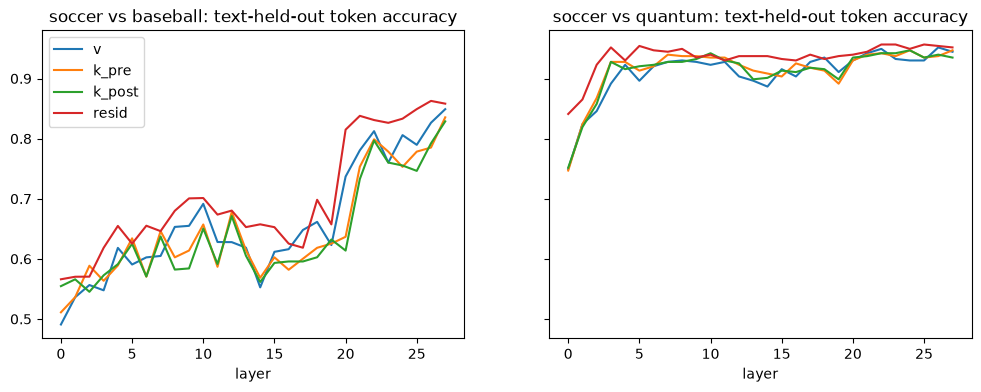

In [7]:
PROBE = [json.loads(l) for l in (DATA / 'exp2_probe_texts.jsonl').read_text().splitlines()]
PX = []
for p in PROBE:
    e = exp2_encode(tok, [{'role': 'user', 'content': p['text']}])
    cap = capture(model, torch.tensor([e.ids]))
    t = {'v': cap.v, 'k_pre': cap.k_pre, 'k_post': cap.k_post, 'resid': cap.resid}
    sl = slice(*e.spans['turn_0'])
    PX.append({r: (flat(t, r) - MU[r])[:, sl] for r in REPS})
    del cap


def probe_data(b, r, layer):
    keep = [k for k, p in enumerate(PROBE) if p['topic'] in ('soccer', b)]
    x = np.concatenate([PX[k][r][layer].numpy() for k in keep])
    y = np.concatenate([np.full(PX[k][r].shape[1], PROBE[k]['topic'] == b) for k in keep])
    g = np.concatenate([np.full(PX[k][r].shape[1], k) for k in keep])
    return x, y, g


def mk():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=2000))


CV, PRB = {}, {}
for b in ('baseball', 'quantum'):
    for r in REPS:
        for l in range(NL):
            x, y, g = probe_data(b, r, l)
            CV[b, r, l] = cross_val_score(mk(), x, y, groups=g, cv=GroupKFold(6)).mean()
            PRB[b, r, l] = mk().fit(x, y)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, b in zip(ax, ('baseball', 'quantum')):
    for r in REPS:
        a.plot([CV[b, r, l] for l in range(NL)], label=r)
    a.set_title(f'soccer vs {b}: text-held-out token accuracy')
    a.set_xlabel('layer')
ax[0].legend()
fig.savefig(FIG / 'm4_probe_cv.png', dpi=110, bbox_inches='tight')


def pb(i, r, l):
    b = 'quantum' if 'quantum' in i else 'baseball'
    idx = content_idx(i)
    return idx, PRB[b, r, l].predict_proba(XC[i][r][l, idx].numpy())[:, 1]


# Dialogue-level AUC: A turns (0-11) vs B turns, using the probe trained only on separate texts.
from sklearn.metrics import roc_auc_score

AUC = {}
for p in PAIRS:
    i = f'{p}-S1'
    sp = META[i]['spans']
    ytok = np.concatenate([np.full(sp[f'turn_{k}'][1] - sp[f'turn_{k}'][0], k >= 14) for k in range(len(DLG[i]['turns'])) if k < 12 or k >= 14])
    for r in REPS:
        for l in range(NL):
            idx, pr = pb(i, r, l)
            keep = np.concatenate([np.arange(*sp[f'turn_{k}']) for k in range(len(DLG[i]['turns'])) if k < 12 or k >= 14])
            AUC[p, r, l] = roc_auc_score(ytok, pr[np.searchsorted(idx, keep)])
for p in PAIRS:
    print(p, {r: (int(np.argmax([AUC[p, r, l] for l in range(NL)])), round(max(AUC[p, r, l] for l in range(NL)), 3)) for r in REPS})

In [8]:
def best_layer(p, r):
    return int(np.argmax([AUC[p, r, l] for l in range(NL)]))


def m2_tok(i, l):
    return MASS[i][l].mean(0).numpy()


# Shift timeline: M1 (token adjacent distance, smoothed), M2 (A-span mass), M4 (P(B)) on one axis set each.
for i in [x for x in IDS if x != 'soccer-S4'] + ['soccer-S4']:
    p = next((q for q in PAIRS if i.startswith(q)), 'soccer-baseball')
    fig, ax = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
    for r in ('v', 'k_pre', 'resid'):
        x, d = tok_adj(i, r, L_MID)
        ax[0].plot(x, smooth(d) / smooth(tok_adj('soccer-S4', r, L_MID)[1]).mean(), label=r, lw=1)
    ax[0].set_ylabel(f'M1 adj cos dist / S4 mean\n(L{L_MID}, w={W})')
    for l in (2, L_MID, NL - 2):
        ax[1].plot(m2_tok(i, l), lw=0.8, label=f'L{l}')
    ax[1].set_ylabel('M2 mass on A span')
    lb = best_layer(p, 'resid')
    for r in ('v', 'resid'):
        x, pr = pb(i, r, best_layer(p, r))
        ax[2].plot(x, smooth(pr, 8), lw=1, label=f'{r} L{best_layer(p, r)}')
    ax[2].set_ylabel(f'M4 P({p.split("-")[1]})')
    for a in ax:
        vlines(a, i)
        a.legend(fontsize=7, loc='upper left')
    ax[0].set_title(i)
    fig.tight_layout()
    fig.savefig(FIG / f'timeline_{i}.png', dpi=100)
    plt.close(fig)


# Probe on the declaration turn (S1, S3): P(B) of declaration tokens vs preceding A turn and following turns.
for i in IDS:
    if DLG[i].get('declaration_turn') is None:
        continue
    p = next(q for q in PAIRS if i.startswith(q))
    out = {}
    for r in ('v', 'resid'):
        idx, pr = pb(i, r, best_layer(p, r))
        def tmean(k):
            a, b = META[i]['spans'][f'turn_{k}']
            return float(pr[(idx >= a) & (idx < b)].mean())
        out[r] = [round(tmean(k), 2) for k in (10, 11, 12, 13, 14, 15, 16, 17)]
    print(i, 'P(B) turns 10..17', out)
for r in ('v', 'resid'):
    for p in PAIRS:
        idx, pr = pb('soccer-S4', r, best_layer(p, r))
        print('S4 control', p, r, 'P(B) turns 10..17', [round(float(pr[(idx >= META['soccer-S4']['spans'][f'turn_{k}'][0]) & (idx < META['soccer-S4']['spans'][f'turn_{k}'][1])].mean()), 2) for k in range(10, 18)])

soccer-baseball-S1 P(B) turns 10..17 {'v': [0.13, 0.05, 0.16, 0.38, 0.76, 0.98, 0.66, 0.63], 'resid': [0.05, 0.02, 0.12, 0.19, 0.62, 0.97, 0.52, 0.57]}
soccer-baseball-S3 P(B) turns 10..17 {'v': [0.13, 0.05, 0.16, 0.38, 0.6, 0.04, 0.16, 0.09], 'resid': [0.05, 0.02, 0.12, 0.19, 0.55, 0.03, 0.07, 0.03]}
soccer-quantum-S1 P(B) turns 10..17 {'v': [0.05, 0.01, 0.18, 0.49, 0.86, 0.99, 0.9, 0.96], 'resid': [0.07, 0.01, 0.25, 0.62, 0.94, 1.0, 0.94, 0.98]}
soccer-quantum-S3 P(B) turns 10..17 {'v': [0.05, 0.01, 0.18, 0.49, 0.26, 0.02, 0.07, 0.01], 'resid': [0.07, 0.01, 0.25, 0.62, 0.3, 0.02, 0.09, 0.01]}
S4 control soccer-baseball v P(B) turns 10..17 [0.13, 0.05, 0.09, 0.04, 0.12, 0.06, 0.14, 0.1]
S4 control soccer-quantum v P(B) turns 10..17 [0.13, 0.05, 0.09, 0.04, 0.12, 0.06, 0.14, 0.1]
S4 control soccer-baseball resid P(B) turns 10..17 [0.05, 0.02, 0.03, 0.02, 0.04, 0.01, 0.03, 0.03]
S4 control soccer-quantum resid P(B) turns 10..17 [0.15, 0.05, 0.11, 0.03, 0.09, 0.07, 0.1, 0.09]


## M5. Change-point detection (PELT)

In [9]:
def cp_signal(i, r, l, k=10, pca=None):
    idx = content_idx(i)
    x = XC[i][r][l, idx].numpy()
    z = pca.transform(x)
    z = np.apply_along_axis(lambda c: smooth(c, 8), 0, z)
    return idx, z


def detect(i, r, l, pen, pca):
    idx, z = cp_signal(i, r, l, pca=pca)
    bk = rpt.Pelt(model='l2', min_size=16, jump=2).fit(z).predict(pen=pen)[:-1]
    return idx[bk] if bk else np.array([], int)


# Penalty is the smallest value that yields zero change points on the no-shift control S4,
# so S4 is the noise floor for detection.
CP = {}
for r in REPS:
    for l in (4, L_MID, NL - 4):
        pca = PCA(10).fit(torch.cat([XC[i][r][l, content_idx(i)] for i in IDS]).numpy())
        idx, z = cp_signal('soccer-S4', r, l, pca=pca)
        pens = np.geomspace(1, 1e9, 200)
        pen = next(pp for pp in pens if len(rpt.Pelt(model='l2', min_size=16, jump=2).fit(z).predict(pen=pp)) == 1)
        for i in IDS:
            CP[r, l, i] = (detect(i, r, l, pen, pca), pen)

print('detected change points (token idx) | ground truth tokens')
for i in IDS:
    gt = {k: turn_tok(i, v) for k, v in events(i).items()}
    print(i, gt)
    for r in REPS:
        for l in (4, L_MID, NL - 4):
            bk, pen = CP[r, l, i]
            err = {k: (int(np.min(np.abs(bk - v))) if len(bk) else None) for k, v in gt.items()}
            print(f'   {r:6s} L{l:<2d} pen={pen:8.1f} bkps={list(map(int, bk))} err={err}')

detected change points (token idx) | ground truth tokens
soccer-baseball-S1 {'declaration': 286, 'B onset': 328}
   v      L4  pen=   133.5 bkps=[84, 104, 260, 280, 333] err={'declaration': 6, 'B onset': 5}
   v      L14 pen= 17834.3 bkps=[] err={'declaration': None, 'B onset': None}
   v      L24 pen= 85044.9 bkps=[] err={'declaration': None, 'B onset': None}
   k_pre  L4  pen= 62225.7 bkps=[140] err={'declaration': 146, 'B onset': 188}
   k_pre  L14 pen= 45529.4 bkps=[] err={'declaration': None, 'B onset': None}
   k_pre  L24 pen= 45529.4 bkps=[287, 344] err={'declaration': 1, 'B onset': 16}
   k_post L4  pen=267384.2 bkps=[287] err={'declaration': 1, 'B onset': 41}
   k_post L14 pen= 56071.7 bkps=[190] err={'declaration': 96, 'B onset': 138}
   k_post L24 pen= 62225.7 bkps=[287, 344] err={'declaration': 1, 'B onset': 16}
   resid  L4  pen=   202.6 bkps=[] err={'declaration': None, 'B onset': None}
   resid  L14 pen=  9547.7 bkps=[] err={'declaration': None, 'B onset': None}
   resid